<a href="https://colab.research.google.com/github/victorm0202/temas_selectos_CD_2026/blob/main/Notebooks/Gene_expression_2026_classification_working.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de datos de expresión genética: TCGA Pan-Cancer

El material de ésta sesión fue adaptado de:
<img src="https://drive.google.com/uc?export=view&id=1CMnXpAQlvpr6KI_0cSxEQnvuNfp7BnBo" alt="img1" width="80%">

Créditos:

- Nelly Sélem, Centro de Ciencias Matemáticas UNAM, México
- Victor Muñiz and Lilia Leticia Ramírez Ramírez CIMAT
- Juan Bizzotto, University of Buenos Aires

<img src="https://drive.google.com/uc?export=view&id=13LN4sSsNugFNzkk8DEFbkID_tuUA1btc" alt="img1" width="80%">



# Introducción

---

## Clasificación en oncología moderna

La clasificación de tumores es fundamental en oncología porque orienta el pronóstico y las estrategias de tratamiento. Históricamente se basaba en la histopatología, pero este enfoque ha cambiado de forma considerable al reconocer que el cáncer presenta una profunda heterogeneidad molecular. Los estudios genómicos a gran escala han demostrado que los tumores de un mismo tipo histológico pueden dividirse en subtipos moleculares distintos, a menudo con diferentes resultados clínicos y respuestas al tratamiento ([TCGA Research Network, 2013](https://www.nature.com/articles/ng.2764)). Esta estratificación molecular es una base de la **medicina de precisión** ([Vogelstein et al., 2013](https://www.science.org/doi/10.1126/science.1235122)).

En el cáncer de próstata, un reto clínico importante es distinguir la enfermedad indolente de la agresiva para evitar tratamientos excesivos. Las herramientas habituales de estratificación de riesgo, como los niveles de **Prostate-Specific Antigen (PSA)** y el **Gleason score**, tienen limitaciones conocidas. Los datos transcriptómicos ofrecen un perfil molecular de alta resolución del tumor y pueden sustentar una estratificación más precisa de los pacientes. Por ejemplo, se validó una firma transcriptómica de 22 genes como predictor independiente de la progresión metastásica; esta ayuda a identificar tanto a quienes requieren tratamiento inmediato como a quienes podrían permanecer bajo vigilancia activa ([Erho et al., 2013](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0064942)).

El análisis de datos transcriptómicos de alta dimensionalidad, donde el número de features (*p* genes) supera ampliamente al número de muestras (*n* pacientes), requiere métodos computacionales especializados. Los algoritmos de **machine learning** son adecuados para esta tarea. Entre los métodos habituales se encuentran Support Vector Machines (SVM), que definen fronteras de decisión en espacios de alta dimensionalidad, y métodos ensemble como Random Forest (RF), que son resistentes al overfitting y proporcionan medidas de feature importance. Estos enfoques ayudan a reducir la complejidad de los datos y a generar **clasificadores útiles para la toma de decisiones clínicas** ([Kourou et al., 2015](https://journalofbigdata.springeropen.com/articles/10.1186/s40537-015-0016-1)).

---

## Acerca de esta práctica

Este documento presenta un flujo de trabajo de machine learning para construir y evaluar un modelo predictivo a partir de datos de expresión génica. El objetivo es **clasificar a los pacientes según su riesgo de recurrencia de la enfermedad en un plazo de tres años**.

El análisis se organiza de la siguiente manera:

1. **Preparación del entorno y carga de datos:** configurar el entorno de Python en Google Colab, cargar o instalar las bibliotecas necesarias y leer los datos preprocesados de expresión génica y datos clínicos.
2. **Exploratory Data Analysis (EDA):** explorar las características de los datos, generar una tabla resumen de variables clínicas y visualizar su estructura mediante métodos no supervisados como Principal Component Analysis (PCA).
3. **Partición de los datos:** dividir el conjunto en training y test para evaluar el modelo de manera imparcial.
4. **Feature selection:** explorar y aplicar métodos para seleccionar un subconjunto relevante de genes y reducir la dimensionalidad.
5. **Entrenamiento inicial y comparación de modelos:** entrenar varios algoritmos de clasificación con cross-validation y comparar su desempeño mediante métricas como Accuracy y Area Under the ROC Curve (AUC).
6. **Feature importance y refinamiento:** examinar la importancia de los genes en un modelo Random Forest entrenado para identificar los más predictivos.
7. **Evaluación con menos features:** volver a entrenar los modelos usando solo las features mejor clasificadas y evaluar su desempeño en el test set reservado.
8. **Métodos de reducción de dimensionalidad:** exploraremos dos estrategias para realizar clasificación en representaciones de baja dimensión de los datos y se compararán los resultados respecto a la selección de variables.

---

## Conjunto de datos y contexto clínico

Los datos de este análisis provienen del proyecto The Cancer Genome Atlas - Prostate Adenocarcinoma (TCGA-PRAD). Este proyecto a gran escala creó un catálogo de alteraciones moleculares en el cáncer de próstata primario mediante la integración de datos genómicos y transcriptómicos con anotaciones clínico-patológicas detalladas de cientos de pacientes ([Weinstein et al., 2013](https://doi.org/10.1038/ng.2764)). Los perfiles de expresión génica se generaron mediante **RNA-Sequencing (RNA-Seq)**; los datos originales se procesaron con pipelines bioinformáticos estandarizados para obtener niveles de expresión normalizados y comparables entre muestras.

Los datos moleculares se combinan con variables clínicas importantes para el pronóstico, como **ISUP grading** (grado histológico), **pathological tumor stage** (extensión del tumor) y niveles sanguíneos de **Prostate-Specific Antigen (PSA)**. La variable de resultado principal es **Biochemical Recurrence (BCR)**, definida por un aumento de PSA después del tratamiento definitivo y utilizada como indicador temprano de recaída ([Freedland & Moul, 2007](https://doi.org/10.1038/sj.pcan.4500923)).

En esta práctica usaremos los datos de expresión génica y estas variables clínicas como features para construir un modelo de machine learning que prediga la recurrencia durante los tres años posteriores al tratamiento inicial (`recurrence.3y`).

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Revisa y analiza brevemente los datos descritos anteriormente que usaremos en ésta práctica. Describe sus características principales e identifica dos retos al trabajar con ellos.
>
> *⏱️ Tiempo estimado: 7 minutos*

# Preparación del entorno y carga de datos

## Carga e inspección de los datos de expresión génica

**Actividad:** ejecuta la siguiente celda de código para cargar los datos de expresión.


In [ ]:
import os
import zipfile
import requests
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, roc_curve, cohen_kappa_score, make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML

In [ ]:
!pip install pyreadr
import pyreadr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.3/788.3 kB 16.4 MB/s eta 0:00:00


### Para usar los datos compartidos en esta carpeta:


Ve a la carpeta compartida `metagenomics`(solo con cuenta de CIMAT):

https://drive.google.com/drive/folders/1LE7qMphzfrUVUlMf6YQNGpJHd-JUm9yf?usp=drive_link

Selecciona Organizar → Añadir acceso directo.

<img src="https://drive.google.com/uc?export=view&id=14UNjWLkh_HR75FFTDEIB4ZyomN3eTyr9" alt="img1" width="80%">

Ve a Todas las ubicaciones. Selecciona Mi unidad y después Añadir.

<img src="https://drive.google.com/uc?export=view&id=1_oB11wBHkGzfHoq0KgCjufYEno9AU4JG" alt="img2" width="40%">


Monta tu Google Drive:


In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


Cambia el directorio de trabajo.

En tu caso: $\verb|/content/drive/My Drive/metagenomics/|$

In [1]:
os.chdir('/content/drive/My Drive/Cursos/optativas_general/notebooks2026/metagenomics/')
!ls

NameError: name 'os' is not defined

In [ ]:
# load the data
!pip install pyreadr
exp = pyreadr.read_r("data/gene_expresion_prostate_cancer.RDS")[None]

In [ ]:
print("Shape: ",exp.shape)
exp.head()

Shape:  (243, 20530)


,ARHGEF10L,HIF3A,RNF17,RNF10,RNF11,RNF13,GTF2IP1,REM1,MTVR2,RTN4RL2,...,TULP2,NPY5R,GNGT2,GNGT1,TULP3,PTRF,BCL6B,GSTK1,SELP,SELS
TCGA-2A-A8VO-01,9.1050,7.1622,0.0000,12.2349,10.9611,10.5777,12.6094,4.9185,0.0000,5.5296,...,1.8713,2.3184,3.4554,0.0,8.9015,12.5682,7.1283,11.0117,8.1436,10.9057
TCGA-2A-A8VT-01,9.6582,4.6591,0.0000,12.1076,11.2948,10.4915,12.5013,3.7936,0.7952,6.1393,...,0.0000,1.3049,2.9973,0.0,8.2230,11.0394,6.8451,10.3673,7.2489,10.5206
TCGA-2A-A8VX-01,9.0166,6.7988,0.0000,12.4550,11.1293,11.0694,12.6353,3.0972,0.5886,4.2959,...,1.3285,0.5886,2.0083,0.0,8.8054,11.9106,4.4368,9.9491,4.8435,11.0117
TCGA-2A-A8W3-01,9.4081,4.8277,0.0000,12.3876,11.0471,10.4217,12.3188,4.6511,0.0000,5.9525,...,0.0000,0.8622,3.4884,0.0,8.3291,12.1733,8.0880,10.1808,7.6060,10.1904
TCGA-2A-AAYF-01,8.7948,5.9371,0.8867,12.1392,11.0526,10.9493,12.8644,3.5374,0.0000,6.3662,...,0.0000,0.8867,2.8810,0.0,8.8017,12.0977,5.9959,10.7471,8.1132,11.2214


La salida de `dim(exp)` muestra la alta dimensionalidad del conjunto de datos: 243 muestras y 20,530 genes como features. Esta situación de `d >> n` (muchas más features que muestras) es habitual en genómica y una de las principales razones para usar machine learning y feature selection.
En éste ejercicio, eliminaremos los genes cuyos valores de expresión son cero en todas las muestras.

In [ ]:
# Filter columns whose sum is greater than 0
exp_filtered = exp.loc[:, exp.sum(axis=0) > 0]


## Carga e inspección de datos fenotípicos

A continuación cargaremos los datos clínicos de la misma cohorte. Esta tabla contiene posibles variables predictoras y la variable de resultado que nos interesa.

**Actividad:** ejecuta la siguiente celda para cargar e inspeccionar los datos fenotípicos.


In [ ]:
pheno = pyreadr.read_r("data/pheno_prostate_cancer.RDS")[None]
#pheno["recurrence.3y"] = pheno["recurrence.3y"].astype(int).astype("category")
pheno["recurrence.3y"] = (
    pheno["recurrence.3y"]
    .astype(int)
    .map({
        0: "No recurrence",
        1: "Recurrence"
    })
    .astype("category")
)
pheno.info()

<class 'pandas.core.frame.DataFrame'>
Index: 243 entries, TCGA-2A-A8VO-01 to TCGA-ZG-A9L9-01
Data columns (total 11 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   age                                  243 non-null    int32   
 1   initial_weight                       128 non-null    object  
 2   initial_pathologic_diagnosis_method  243 non-null    object  
 3   histological_type                    243 non-null    object  
 4   ISUP_group                           243 non-null    category
 5   pathologic_T_simple                  241 non-null    category
 6   laterality                           240 non-null    object  
 7   PFI                                  243 non-null    int32   
 8   PFI.time                             243 non-null    int32   
 9   PSA                                  234 non-null    float64 
 10  recurrence.3y                        243 non-null    category
dty

La salida muestra varias variables clínicas importantes, entre ellas `age`, `ISUP_group`, `pathologic_T_simple` y `PSA`. También contiene la variable objetivo de la clasificación: `recurrence.3y`, codificada como `1` si hubo recurrencia y `0` si no la hubo durante los tres años siguientes.

## Generación de un resumen clínico inicial

En investigación clínica es habitual generar un resumen descriptivo de las características iniciales de una cohorte. Esta «Tabla 1» muestra la distribución de las variables principales según el resultado y ayuda a entender la composición de la cohorte.

**Actividad:** ejecuta la siguiente celda para generar la tabla resumen.


In [ ]:
from IPython.display import display

# Select clinical variables
vars_table1 = ["age", "PSA", "ISUP_group", "pathologic_T_simple", "recurrence.3y"]
pheno_table = pheno[vars_table1].copy()

# Continuous and categorical variables
continuous_vars = ["age", "PSA"]
categorical_vars = ["ISUP_group", "pathologic_T_simple", "recurrence.3y"]

summary_rows = []

# Summary of continuous variables: mean (SD)
for col in continuous_vars:
    mean = pheno_table[col].mean()
    sd = pheno_table[col].std()
    summary_rows.append({
        "Variable": col,
        "Summary": f"{mean:.2f} ({sd:.2f})"
    })

# Summary of categorical variables: n (%)
for col in categorical_vars:
    counts = pheno_table[col].value_counts(dropna=False)
    total = len(pheno_table)

    for level, n in counts.items():
        pct = 100 * n / total
        summary_rows.append({
            "Variable": f"{col}: {level}",
            "Summary": f"{n} ({pct:.1f}%)"
        })

summary_table = pd.DataFrame(summary_rows)
display(HTML(summary_table.to_html(index=False)))

Variable,Summary
age,60.73 (6.30)
PSA,11.72 (13.53)
ISUP_group: 5,83 (34.2%)
ISUP_group: 2,64 (26.3%)
ISUP_group: 3,49 (20.2%)
ISUP_group: 4,31 (12.8%)
ISUP_group: 1,16 (6.6%)
pathologic_T_simple: T3,158 (65.0%)
pathologic_T_simple: T2,75 (30.9%)
pathologic_T_simple: T4,8 (3.3%)


# Análisis exploratorio no supervisado

Antes de construir modelos predictivos, conviene realizar un Exploratory Data Analysis (EDA) para comprender la estructura de los datos. Utilizaremos métodos no supervisados, que analizan los datos sin usar las etiquetas del resultado (es decir, el estado de recurrencia). Así podremos identificar las principales fuentes de variación y observar si las muestras se agrupan de forma natural según sus perfiles moleculares.

## Reducción de dimensionalidad.

El objetivo es resumir la información de las variables originales (niveles de expresión) en algunos componentes que combinan dicha información bajo cierto criterio.

Esta visualización permite evaluar si los principales ejes de variación del transcriptoma se relacionan con grupos clínicos o biológicos conocidos.

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza PCA y tSNE sobre los datos de expresión filtrados. Verifica si puedes detectar patrones interesantes considerando las siguientes variables clínicas: `ISUP_group`, `pathologic_T_simple` y `recurrence.3y`.

> Discute tus resultados.

> *⏱️ Tiempo estimado: 10 minutos*

# Partición de los datos: creación de training y test sets

## Objetivo y metodología

Un principio básico del supervised machine learning es entrenar un modelo con una parte de los datos y evaluar su desempeño con otra parte, que no haya visto durante el entrenamiento. Esto es esencial por dos motivos:

1. **Evitar overfitting:** ocurre cuando el modelo aprende demasiado bien los datos de entrenamiento, incluido su ruido, y no logra generalizar a datos nuevos. Evaluarlo con un test set independiente permite estimar su capacidad de generalización.
2. **Obtener una estimación imparcial del desempeño:** el resultado en el test set aproxima cómo funcionaría el modelo con pacientes nuevos.

Primero combinaremos los datos de expresión (`exp`) y los datos clínicos (`pheno`) en una tabla. Después haremos una **stratified split**, que conserva en los training y test sets la proporción original de cada clase (por ejemplo, 30 % con recurrencia y 70 % sin recurrencia). Esto es especialmente importante si las clases están desbalanceadas.

## Parámetros de la partición

La evaluación depende de cómo se dividen los datos. Ajustarás dos parámetros que controlan este proceso; experimentar con ellos ayuda a comprender la metodología de machine learning.

**Parámetros modificables:**

* `proportion.train`: valor entre 0 y 1 que determina la proporción de datos asignada al **training set**. Son habituales 0.7 y 0.8 (70 % y 80 %).
    * **Efecto:** un training set más grande ofrece más datos para aprender, pero deja menos muestras para el test set, lo que puede aumentar la variabilidad de la evaluación final.
* `set.seed(value)`: inicializa el generador de números aleatorios con un entero. Como la partición utiliza muestreo aleatorio, fijar la semilla produce *exactamente la misma partición cada vez que se ejecuta el código*.
    * **Efecto:** garantiza la **reproducibilidad**. Si cambias la semilla (por ejemplo, a `456`), obtendrás otra partición reproducible. Esto permite estudiar cuánto depende el desempeño de las muestras asignadas a training y test. Mantén la misma semilla dentro de cada experimento.



In [ ]:
proportion_train = 0.7
random_seed = 42

# Expression and phenotype features
gene_features = exp_filtered.columns.tolist()

# Merge by index
table = exp_filtered.merge(pheno_table, left_index=True, right_index=True)

# Original response variable
y_original = table["recurrence.3y"]

# Encode recurrence.3y


label_encoder = LabelEncoder()

table["Class"] = label_encoder.fit_transform(y_original)

# Check encoding
label_mapping = pd.DataFrame({
    "original_label": label_encoder.classes_,
    "encoded_label": range(len(label_encoder.classes_))
})

display(label_mapping)


,original_label,encoded_label
0,No recurrence,0
1,Recurrence,1


In [ ]:
# Stratified train/test split
table_training, table_testing = train_test_split(
    table,
    train_size=proportion_train,
    random_state=random_seed,
    stratify=table["Class"]
)

# Check class proportions
print("Training class proportions:")
print(table_training["Class"].value_counts(normalize=True))

print("\nTesting class proportions:")
print(table_testing["Class"].value_counts(normalize=True))

Training class proportions:
Class
0    0.705882
1    0.294118
Name: proportion, dtype: float64

Testing class proportions:
Class
0    0.69863
1    0.30137
Name: proportion, dtype: float64


# Feature selection: reducción del número de genes

En conjuntos de datos genómicos de alta dimensionalidad hay muchas más features (genes) que muestras. Esta «maldición de la dimensionalidad» puede causar overfitting y reducir el desempeño. En este paso seleccionaremos un subconjunto más pequeño e informativo de genes.

Tu tarea consiste en elegir **un método de selección** y el número de genes (`n.genes`) que usarás. Ambas decisiones forman parte del diseño experimental e influyen en los resultados del modelo.

* **`num_genes = 200`**: este parámetro establece el número exacto de genes seleccionados para entrenar el modelo. El valor óptimo depende de los datos y debe evaluarse.

A continuación se presentan cuatro criterios para seleccionar los genes. Elige uno para tu análisis.

1. **Random selection:**
    * **Motivo:** sirve como baseline o control. Supone que ningún gen es más importante que otro y permite comparar los métodos restantes.
2. **Highest variance:**
    * **Motivo:** selecciona los genes con mayor variación entre las muestras del training set, bajo la hipótesis de que pueden contener más información para distinguir las clases.
3. **Bibliography-based selection:**
    * **Motivo:** usa conocimiento del área para seleccionar genes identificados previamente en la literatura como relevantes para la enfermedad estudiada (por ejemplo, cáncer de próstata).
4. **Differential Gene Expression (DGE):**
    * **Motivo:** identifica los genes cuyos niveles de expresión difieren más significativamente entre las clases (por ejemplo, con recurrencia frente a sin recurrencia). Selecciona los genes con mayor asociación estadística con el resultado.


In [ ]:
num_genes = 200

Método 1: Random selection (baseline)


In [ ]:
np.random.seed(random_seed)
random_genes = np.random.choice(exp.columns, size=num_genes, replace=False).tolist()

Método 2: Highest variance


In [ ]:
gene_variances = table_training[gene_features].var(axis=0)
top_var_genes_sorted = gene_variances.sort_values(ascending=False).index.tolist()
top_var_genes = top_var_genes_sorted[:num_genes]

Método 3: Bibliography-based selection


In [ ]:
with open("data/genes_cancer_prostata_bibliografia.txt", "r") as file:
    bibliography_genes = file.read().splitlines()

# Assumes the list is already pre-ranked
bibliography_genes = bibliography_genes[:num_genes]

Método 4: Differential Gene Expression (DGE)

Usaremos la prueba Wilcoxon rank-sum (Mann-Whitney U), con las siguientes hipótesis nula y alternativa:

- $H_0$: los valores de expresión génica de ambos grupos (con recurrencia y sin recurrencia) provienen de la misma distribución.
- $H_1$: los valores de expresión génica de ambos grupos provienen de distribuciones diferentes.

Un p-value pequeño (por ejemplo, $p < 0.05$) permite rechazar $H_0$.


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Investiga sobre las características y demás detalles de DGE.

> - ¿En qué consiste la prueba de Wilcoxon usada?
> - ¿Bajo qué distribución se realiza la prueba de hipótesis?

> *⏱️ Tiempo estimado: 7 minutos*

In [ ]:
from scipy.stats import mannwhitneyu

def calculate_p_values(expression_data, labels):
    p_values = {}

    for gene in expression_data.columns:
        group_values = [
            expression_data.loc[labels == group, gene].dropna()
            for group in labels.unique()
        ]

        test_result = mannwhitneyu(
            group_values[0],
            group_values[1],
            alternative="two-sided"
        )
        # Calculates a p-value for each gene based on differential expression between two classes
        p_values[gene] = test_result.pvalue

    return pd.Series(p_values)

In [ ]:
p_values = calculate_p_values(
    table_training[gene_features],
    table_training["Class"]
)

In [ ]:
# Create a DataFrame with the results and rank genes by lowest p-value
ranked_DGE_genes = (
    pd.DataFrame({
        "Gene": p_values.index,
        "PValue": p_values.values
    })
    .sort_values("PValue")
    .reset_index(drop=True)
)

# Select the first num_genes with the lowest p-values
top_DGE_genes = ranked_DGE_genes.head(num_genes)["Gene"].tolist()

## Selecciona un subconjunto de genes

Elige uno de los subconjuntos generados anteriormente para usarlo como entrada de los modelos de machine learning (`random.genes`, `top_DGE_genes`, `bibliography_genes` o `top_var_genes`).

Puedes cambiar de subconjunto y comparar los resultados.


In [ ]:
# SELECT
genes_to_use = top_DGE_genes
#genes_to_use = bibliography_genes
#genes_to_use = top_var_genes
#genes_to_use = gene_features  # Use all genes for the model

## Crea las tablas de training y validation

Al principio usaremos solo genes como features. **También podríamos considerar los datos fenotípicos**.


In [ ]:
X_train = table_training[genes_to_use]
y_train = table_training["Class"]

X_test = table_testing[genes_to_use]
y_test = table_testing["Class"]

In [ ]:
# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=random_seed
)

# Models
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, class_weight="balanced"))
    ]),

    "RF": RandomForestClassifier(
        random_state=random_seed, class_weight="balanced"
    ),

    "LOGREG": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])
}


## Métricas de evaluación:

- Accuracy
- Cohen's Kappa


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Investiga sobre la métrica Cohen's Kappa y di sus principales características para entender cómo interpretarla.


> *⏱️ Tiempo estimado: 5 minutos*

In [ ]:
# Scoring metrics
scoring = {
    "accuracy": "accuracy",
    "kappa": make_scorer(cohen_kappa_score)
}

cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = {
        "Accuracy_mean": scores["test_accuracy"].mean(),
        "Accuracy_sd": scores["test_accuracy"].std(),
        "Kappa_mean": scores["test_kappa"].mean(),
        "Kappa_sd": scores["test_kappa"].std()
    }

metrics_summary_accuracy_kappa = pd.DataFrame(cv_results).T

display(metrics_summary_accuracy_kappa.round(3))

,Accuracy_mean,Accuracy_sd,Kappa_mean,Kappa_sd
KNN,0.753,0.058,0.417,0.111
SVM,0.747,0.098,0.445,0.199
RF,0.753,0.066,0.347,0.150
LOGREG,0.712,0.080,0.326,0.152


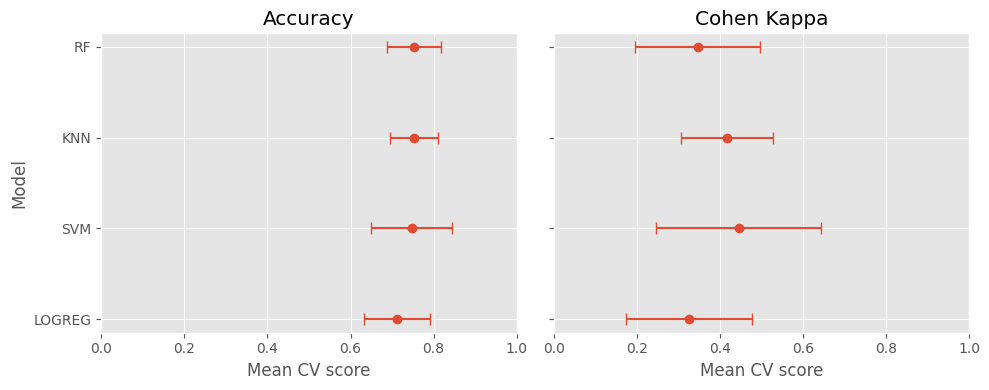

In [ ]:
plt.style.use("ggplot")

metrics_to_plot = {
    "Accuracy": ("Accuracy_mean", "Accuracy_sd"),
    "Cohen Kappa": ("Kappa_mean", "Kappa_sd")
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharey=True
)

plot_data = metrics_summary_accuracy_kappa.copy()
plot_data["Model"] = plot_data.index

for ax, (metric_name, (mean_col, sd_col)) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(mean_col)

    ax.errorbar(
        x=data[mean_col],
        y=data["Model"],
        xerr=data[sd_col],
        fmt="o",
        capsize=4
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Mean CV score")
    ax.set_xlim(0, 1)

axes[0].set_ylabel("Model")

plt.tight_layout()
plt.show()

## Entrenamiento para ROC (AUC)

Después de la evaluación inicial, entrenaremos y compararemos los modelos mediante curvas Receiver Operating Characteristic (ROC) y su Area Under the Curve (AUC). Esta métrica es útil para evaluar clasificadores, especialmente cuando las clases están desbalanceadas, porque resume la capacidad del modelo para distinguirlas a través de todos los umbrales posibles. En comparación con Accuracy, AUC es menos sensible a resultados engañosos causados por una clase mucho más numerosa que la otra.


In [ ]:
for encoded_label, original_label in enumerate(label_encoder.classes_):
    print(f"{encoded_label} = {original_label}")

0 = No recurrence
1 = Recurrence


In [ ]:

# recurrence = 1 was encoded as 1; this is the positive class
positive_class = 1
negative_class = 0

# Sensitivity: ability to detect Recurrence
sensitivity_scorer = make_scorer(
    recall_score,
    pos_label=positive_class
)

# Specificity: ability to detect No_recurrence
specificity_scorer = make_scorer(
    recall_score,
    pos_label=negative_class
)

# Cohen's Kappa measures how well predicted labels agree with true labels, correcting for chance agreement.
# A value close to 1 indicates high agreement, while 0 indicates performance equivalent to chance.

scoring = {
    "roc_auc": "roc_auc",
    "sensitivity": sensitivity_scorer,
    "specificity": specificity_scorer
}

cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = {
        "ROC_AUC_mean": scores["test_roc_auc"].mean(),
        "ROC_AUC_sd": scores["test_roc_auc"].std(),
        "Sensitivity_mean": scores["test_sensitivity"].mean(),
        "Sensitivity_sd": scores["test_sensitivity"].std(),
        "Specificity_mean": scores["test_specificity"].mean(),
        "Specificity_sd": scores["test_specificity"].std()
    }

metrics_summary_roc = pd.DataFrame(cv_results).T

display(metrics_summary_roc)

,ROC_AUC_mean,ROC_AUC_sd,Sensitivity_mean,Sensitivity_sd,Specificity_mean,Specificity_sd
KNN,0.772083,0.066178,0.60,0.063246,0.816667,0.085797
SVM,0.825833,0.102483,0.72,0.116619,0.758333,0.092796
RF,0.802500,0.098666,0.42,0.116619,0.891667,0.089753
LOGREG,0.757500,0.107639,0.54,0.048990,0.783333,0.096465


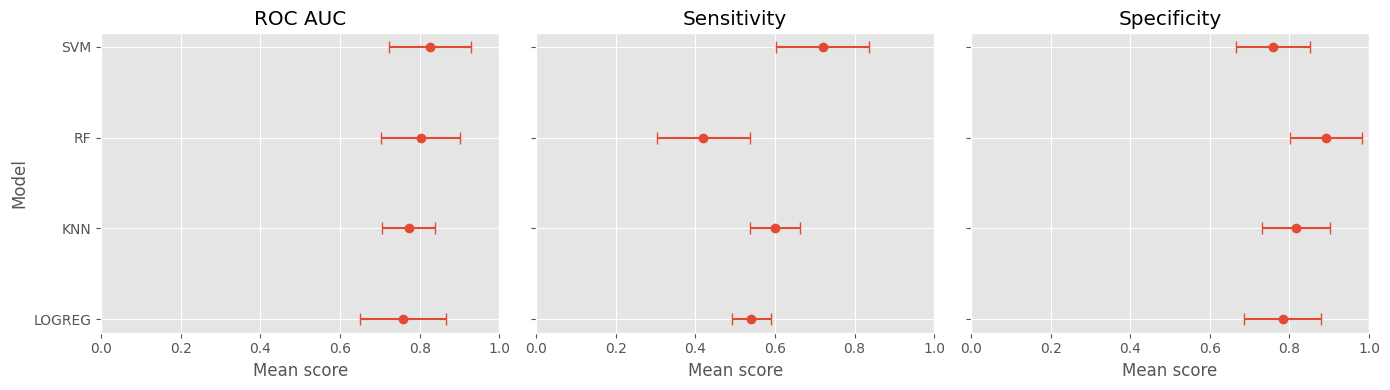

In [ ]:
plt.style.use("ggplot")

metrics_to_plot = {
    "ROC AUC": ("ROC_AUC_mean", "ROC_AUC_sd"),
    "Sensitivity": ("Sensitivity_mean", "Sensitivity_sd"),
    "Specificity": ("Specificity_mean", "Specificity_sd")
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4),
    sharey=True
)

plot_data = metrics_summary_roc.copy()
plot_data["Model"] = plot_data.index

for ax, (metric_name, (mean_col, sd_col)) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(mean_col)

    ax.errorbar(
        x=data[mean_col],
        y=data["Model"],
        xerr=data[sd_col],
        fmt="o",
        capsize=4
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Mean score")
    ax.set_xlim(0, 1)

axes[0].set_ylabel("Model")

plt.tight_layout()
plt.show()

# Evaluación de modelos con datos de test y comparación con training y validation

Después de cross-validation, evaluaremos los modelos entrenados en el test set independiente para estimar su desempeño con datos nuevos. Este paso permite evaluar la generalización y detectar overfitting.

Pasos:

1. **Predecir en el test set:** usar cada modelo entrenado (KNN, SVM, RF y LogReg) para predecir las clases de las muestras en `table.testing`.
2. **Calcular métricas de desempeño:** obtener Accuracy, AUC, Sensitivity y Specificity a partir de las predicciones y las etiquetas reales del test set.
3. **Comparar con cross-validation:** contrastar el desempeño en test con el promedio obtenido mediante cross-validation de 5 folds en el training set.
4. **Identificar overfitting:**
5. **Visualizar la comparación:** representar las métricas de training (mediante cross-validation) y test (por ejemplo, AUC) para evaluar visualmente la generalización de cada modelo.

Este procedimiento ofrece una estimación más realista de la capacidad predictiva con datos nuevos que el modelo no ha visto.


In [ ]:
performance_summary_roc = {}

positive_class = 1
negative_class = 0

for model_name, model in models.items():
    # Train the model using the full training set
    model.fit(X_train, y_train)

    # Class predictions
    predictions_class = model.predict(X_test)

    # Probability predictions
    predictions_prob = model.predict_proba(X_test)

    # Probability of the positive class
    positive_class_index = list(model.classes_).index(positive_class)
    predictions_prob_positive = predictions_prob[:, positive_class_index]

    # Metrics
    auc_value = roc_auc_score(y_test, predictions_prob_positive)
    accuracy = accuracy_score(y_test, predictions_class)
    kappa = cohen_kappa_score(y_test, predictions_class)

    sensitivity = recall_score(
        y_test,
        predictions_class,
        pos_label=positive_class
    )

    specificity = recall_score(
        y_test,
        predictions_class,
        pos_label=negative_class
    )

    performance_summary_roc[model_name] = {
        "AUC": auc_value,
        "Accuracy": accuracy,
        "Kappa": kappa,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    }

performance_summary_roc = pd.DataFrame(performance_summary_roc)

display(performance_summary_roc.round(3))

,KNN,SVM,RF,LOGREG
AUC,0.696,0.681,0.771,0.619
Accuracy,0.658,0.644,0.740,0.644
Kappa,0.236,0.284,0.339,0.196
Sensitivity,0.545,0.727,0.455,0.500
Specificity,0.706,0.608,0.863,0.706


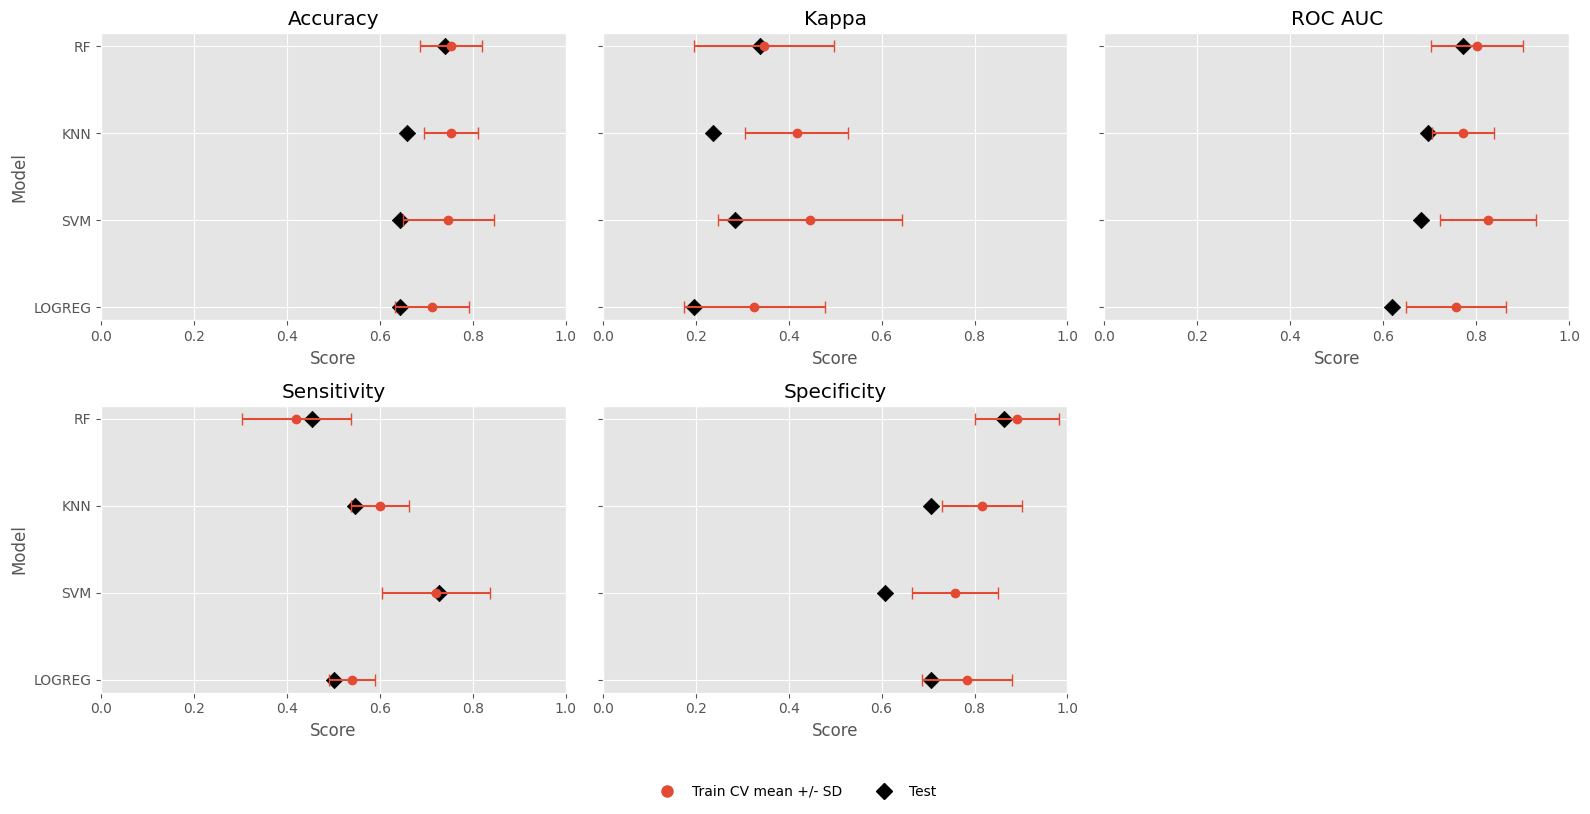

In [ ]:
from matplotlib.lines import Line2D

plt.style.use("ggplot")

# Join training/CV results
training_summary = metrics_summary_accuracy_kappa.join(metrics_summary_roc)

# Test: performance_summary_roc has metrics as rows and models as columns
test_summary = performance_summary_roc.T.copy()

metrics_to_plot = {
    "Accuracy": {
        "cv_mean": "Accuracy_mean",
        "cv_sd": "Accuracy_sd",
        "test": "Accuracy"
    },
    "Kappa": {
        "cv_mean": "Kappa_mean",
        "cv_sd": "Kappa_sd",
        "test": "Kappa"
    },
    "ROC AUC": {
        "cv_mean": "ROC_AUC_mean",
        "cv_sd": "ROC_AUC_sd",
        "test": "AUC"
    },
    "Sensitivity": {
        "cv_mean": "Sensitivity_mean",
        "cv_sd": "Sensitivity_sd",
        "test": "Sensitivity"
    },
    "Specificity": {
        "cv_mean": "Specificity_mean",
        "cv_sd": "Specificity_sd",
        "test": "Specificity"
    }
}

plot_data = training_summary.copy()
plot_data["Model"] = plot_data.index

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 8),
    sharey=True
)

axes = axes.flatten()

for ax, (metric_name, cols) in zip(axes, metrics_to_plot.items()):
    data = plot_data.sort_values(cols["cv_mean"]).copy()

    # Train / CV
    ax.errorbar(
        x=data[cols["cv_mean"]],
        y=data["Model"],
        xerr=data[cols["cv_sd"]],
        fmt="o",
        capsize=4,
        label="Train CV mean +/- SD"
    )

    # Test
    test_values = test_summary.loc[data["Model"], cols["test"]]

    ax.scatter(
        test_values,
        data["Model"],
        marker="D",
        s=70,
        color="black",
        label="Test"
    )

    ax.set_title(metric_name)
    ax.set_xlabel("Score")
    ax.set_xlim(0, 1)
    #ax.legend(loc="lower right")

axes[0].set_ylabel("Model")
axes[3].set_ylabel("Model")

# Turn off the empty panel, because there are 5 metrics and the grid has 6 slots
axes[-1].axis("off")

#---
legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        #color="tab:blue",
        label="Train CV mean +/- SD",
        linestyle="None",
        markersize=8
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        color="black",
        label="Test",
        linestyle="None",
        markersize=8
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


#---

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza un análisis de los resultados obtenidos.

> - ¿Qué modelo es mejor para ti?
> - ¿Identificas sobreajuste con algún método?

> *⏱️ Tiempo estimado: 5 minutos*

# Feature importance y refinamiento

## Feature importance con Random Forest

Esta sección cuantifica la **importancia relativa de cada gen** en el modelo Random Forest entrenado. Comprender la feature importance es útil por dos motivos:

1. **Interpretación biológica:** ayuda a identificar genes que influyen más en la predicción de recurrencia bioquímica y que podrían señalar mecanismos biológicos relevantes.
2. **Feature selection:** la clasificación de genes por importancia permite elegir, a partir de los datos, un subconjunto más pequeño para modelos más sencillos y potencialmente más robustos.

Representaremos estas medidas para identificar claramente los genes con mayor contribución.


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Implementa un clasificador basado en RF e identifica los 100 genes más importantes. Realiza una gráfica apropiada para mostrar éstas variables
>
> *⏱️ Tiempo estimado: 7 minutos*

## Entrenamiento y evaluación de todos los modelos con las Top-K features

Esta sección compara el desempeño de **todos los modelos entrenados con el conjunto completo de genes** (o con el subconjunto seleccionado inicialmente) y el de **los modelos reentrenados usando solo las `k` features más importantes**.

El objetivo es determinar si un modelo más sencillo, construido con menos features pero altamente informativas, alcanza un desempeño comparable o superior. Esto permite evaluar la estrategia de feature selection.


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Repite el ejercicio de las secciones anteriores, con los mismos clasificadores y métricas de evaluación, pero ahora con los $K$ genes más importantes dados por RF. Discute las diferencias que encuentres y cuál enfoque de selección de variables crees que sea mejor para ésta aplicación

>
> *⏱️ Tiempo estimado: 15 minutos*

# Reducción de dimensión para tareas de clasificación

## Primer enfoque: UMAP + modelos de clasificación

### Paso de reducción de dimensionalidad

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Utiliza UMAP para hacer reducción de dimensionalidad no-lineal en los datos de entrenamiento. Elige un número de componentes adecuado para entrenar los mismos modelos de clasificación usados en las secciones anteriores y muestra los resultados obtenidos en los datos de prueba.

> ¿Observas alguna ventaja al usar éste enfoque?

> *⏱️ Tiempo estimado: 15 minutos*

## Segundo enfoque: Deep autoencoder.

Aprenderemos una representación de baja dimensionalidad adecuada para la clasificación.

En este enfoque utilizaremos todas las features.

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import platform

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, cohen_kappa_score, recall_score
from tqdm.notebook import tqdm

In [ ]:
if platform.system() == 'Darwin': # si se utiliza macOS
    av1 = torch.backends.mps.is_available()
    # Comprobar que esta instalación de PyTorch se compiló con MPS activado.
    av2 = torch.backends.mps.is_built()
    if(av1==av2==True):
        print('MPS available?',av1,'MPS built?',av2)
        device = torch.device('mps')
    else:
        device = torch.device('cpu')
else:
    # Comprobar si hay una GPU disponible
    if torch.cuda.is_available():
        device = torch.device('cuda')
    else:
        device = torch.device('cpu')
print("Device:",device)

Device: cuda


In [ ]:
# Reproducibilidad
random_seed = 420

np.random.seed(random_seed)
torch.manual_seed(random_seed)

In [ ]:
#genes_to_use = top_DGE_genes
#genes_to_use = bibliography_genes
#genes_to_use = top_var_genes
genes_to_use = gene_features  # Utilizar todos los genes en el modelo

X_train = table_training[genes_to_use]
y_train = table_training["Class"]

X_test = table_testing[genes_to_use]
y_test = table_testing["Class"]

In [ ]:
# Escalar los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir a tensores de PyTorch
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1).to(device)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1).to(device)

# Crear el dataset y el dataloader de training
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

Arquitectura del autoencoder

In [ ]:
class ClassifierAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1200),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1200, 1000),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1000, 800),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(800, 500),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(500, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 500),
            nn.ReLU(),
            nn.Linear(500, 800),
            nn.ReLU(),
            nn.Linear(800, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1200),
            nn.ReLU(),
            nn.Linear(1200, input_dim)
        )

        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        class_logits = self.classifier(z)

        return x_reconstructed, class_logits, z

In [ ]:
input_dim = X_train_scaled.shape[1]

model = ClassifierAutoencoder(
    input_dim=input_dim,
    latent_dim=300
).to(device)

reconstruction_loss_fn = nn.MSELoss()
classification_loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

num_epochs = 100

alpha = 0.2  # peso de la reconstruction loss
beta = 1.0 - alpha  # peso de la classification loss

In [ ]:
training_history = []

progress_bar = tqdm(range(num_epochs), desc="Training ClassifierAutoencoder")

for epoch in progress_bar:
    model.train()

    epoch_total_loss = 0
    epoch_reconstruction_loss = 0
    epoch_classification_loss = 0

    all_train_probs = []
    all_train_preds = []
    all_train_labels = []

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        X_reconstructed, class_logits, _ = model(batch_X)

        reconstruction_loss = reconstruction_loss_fn(X_reconstructed, batch_X)
        classification_loss = classification_loss_fn(class_logits, batch_y)

        total_loss = alpha * reconstruction_loss + beta * classification_loss

        total_loss.backward()
        optimizer.step()

        epoch_total_loss += total_loss.item()
        epoch_reconstruction_loss += reconstruction_loss.item()
        epoch_classification_loss += classification_loss.item()

        train_probs = torch.sigmoid(class_logits).detach().cpu().numpy().ravel()
        train_preds = (train_probs >= 0.5).astype(int)
        train_labels = batch_y.detach().cpu().numpy().ravel()

        all_train_probs.extend(train_probs)
        all_train_preds.extend(train_preds)
        all_train_labels.extend(train_labels)

    mean_total_loss = epoch_total_loss / len(train_loader)
    mean_reconstruction_loss = epoch_reconstruction_loss / len(train_loader)
    mean_classification_loss = epoch_classification_loss / len(train_loader)

    train_accuracy = accuracy_score(all_train_labels, all_train_preds)

    try:
        train_auc = roc_auc_score(all_train_labels, all_train_probs)
    except ValueError:
        train_auc = np.nan

    training_history.append({
        "epoch": epoch + 1,
        "total_loss": mean_total_loss,
        "reconstruction_loss": mean_reconstruction_loss,
        "classification_loss": mean_classification_loss,
        "train_accuracy": train_accuracy,
        "train_auc": train_auc
    })

    progress_bar.set_postfix({
        "loss": f"{mean_total_loss:.4f}",
        "class_loss": f"{mean_classification_loss:.4f}",
        "acc": f"{train_accuracy:.3f}",
        "auc": f"{train_auc:.3f}"
    })

training_history = pd.DataFrame(training_history)

display(training_history.tail())

Training ClassifierAutoencoder:   0%|          | 0/100 [00:00<?, ?it/s]

,epoch,total_loss,reconstruction_loss,classification_loss,train_accuracy,train_auc
95,96,0.182114,0.862815,0.011938,0.988235,1.000000
96,97,0.326981,0.861524,0.193345,0.994118,0.993667
97,98,0.181629,0.858851,0.012324,0.988235,0.999750
98,99,0.181108,0.839296,0.016561,0.982353,1.000000
99,100,0.184358,0.827996,0.023449,0.988235,1.000000


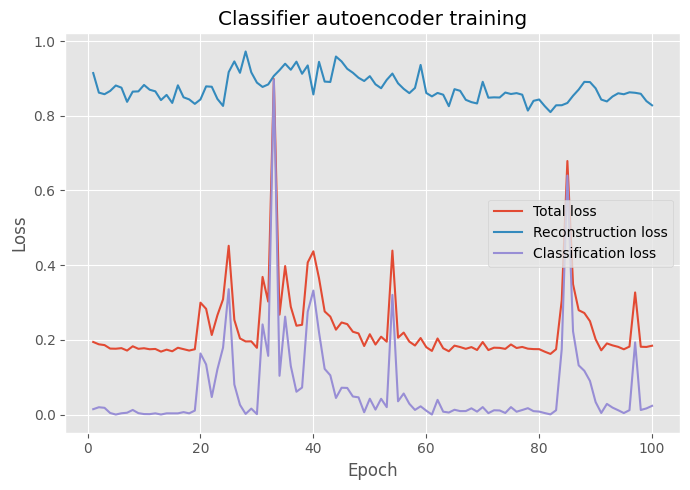

In [ ]:
plt.style.use("ggplot")

plt.figure(figsize=(7, 5))

plt.plot(training_history["epoch"], training_history["total_loss"], label="Total loss")
plt.plot(training_history["epoch"], training_history["reconstruction_loss"], label="Reconstruction loss")
plt.plot(training_history["epoch"], training_history["classification_loss"], label="Classification loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Classifier autoencoder training")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Evaluar el modelo en el test set
model.eval()

with torch.no_grad():
    _, test_logits, test_latent = model(X_test_tensor)

    # Obtener probabilidades y predicciones
    test_prob = torch.sigmoid(test_logits).detach().cpu().numpy().ravel()
    test_pred = (test_prob >= 0.5).astype(int)

y_test_np = y_test.values

positive_class = 1
negative_class = 0

# Calcular y mostrar las métricas de evaluación
autoencoder_results = {
    "AUC": roc_auc_score(y_test_np, test_prob),
    "Accuracy": accuracy_score(y_test_np, test_pred),
    "Kappa": cohen_kappa_score(y_test_np, test_pred),
    "Sensitivity": recall_score(y_test_np, test_pred, pos_label=positive_class),
    "Specificity": recall_score(y_test_np, test_pred, pos_label=negative_class)
}

autoencoder_results = pd.DataFrame(
    autoencoder_results,
    index=["Classifier_Autoencoder"]
)

display(autoencoder_results.round(3))

,AUC,Accuracy,Kappa,Sensitivity,Specificity
Classifier_Autoencoder,0.673,0.644,0.132,0.364,0.765


Podemos visualizar el latent space que aprendió el autoencoder y que se utilizó para la clasificación.

In [ ]:
model.eval()

with torch.no_grad():
    # Extraer las representaciones latentes
    z_train = model.encoder(X_train_tensor.to(device))
    z_test = model.encoder(X_test_tensor.to(device))

# Convertir a NumPy y crear DataFrames
z_train = z_train.detach().cpu().numpy()
z_test = z_test.detach().cpu().numpy()

z_train_df = pd.DataFrame(
    z_train,
    columns=[f"Latent_{i+1}" for i in range(z_train.shape[1])]
)

z_train_df["Class"] = list(y_train)
z_train_df["Set"] = "Train"

z_test_df = pd.DataFrame(
    z_test,
    columns=[f"Latent_{i+1}" for i in range(z_test.shape[1])]
)

z_test_df["Class"] = list(y_test)
z_test_df["Set"] = "Test"

# Concatenar y añadir las etiquetas de clase
latent_df = pd.concat(
    [z_train_df, z_test_df],
    axis=0,
    ignore_index=True
)

latent_df["Class_label"] = latent_df["Class"].map({
    0: "No recurrence",
    1: "Recurrence"
})

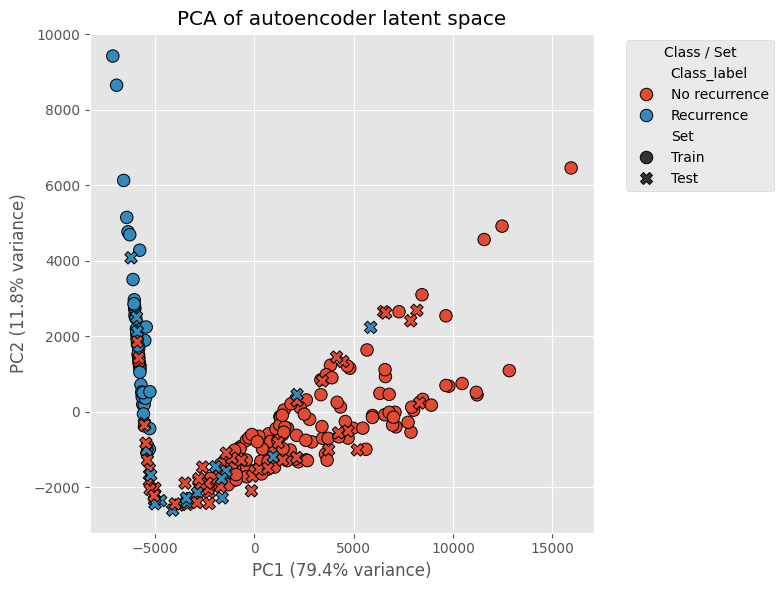

In [ ]:
from sklearn.decomposition import PCA

latent_features = latent_df.filter(regex="^Latent_")

pca_latent = PCA(n_components=2)
latent_pca = pca_latent.fit_transform(latent_features)

latent_pca_df = pd.DataFrame(
    latent_pca,
    columns=["PC1", "PC2"]
)

latent_pca_df["Class_label"] = latent_df["Class_label"]
latent_pca_df["Set"] = latent_df["Set"]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=latent_pca_df,
    x="PC1",
    y="PC2",
    hue="Class_label",
    style="Set",
    s=80,
    edgecolor="black"
)

plt.title("PCA of autoencoder latent space")
plt.xlabel(f"PC1 ({pca_latent.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_latent.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.legend(title="Class / Set", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Mejora adicional: early stopping para evitar overfitting.

In [ ]:
input_dim = X_train_scaled.shape[1]

model = ClassifierAutoencoder(
    input_dim=input_dim,
    latent_dim=300
).to(device)

reconstruction_loss_fn = nn.MSELoss()
classification_loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

alpha = 1.0  # peso de la reconstruction loss
beta = 1.0 #- alpha  # peso de la classification loss

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

random_seed = 123
np.random.seed(random_seed)
torch.manual_seed(random_seed)

# Dividir los datos de training en conjuntos internos de training y validation
X_train_inner, X_val, y_train_inner, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=random_seed,
    stratify=y_train
)

# Convertir a tensores de PyTorch para training y validation internos
X_train_inner_tensor = torch.tensor(X_train_inner, dtype=torch.float32).to(device)
y_train_inner_tensor = torch.tensor(y_train_inner.values, dtype=torch.float32).view(-1, 1).to(device)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1).to(device)

# Crear el dataset y el dataloader para training interno
train_inner_dataset = TensorDataset(X_train_inner_tensor, y_train_inner_tensor)

train_loader = DataLoader(
    train_inner_dataset,
    batch_size=32,
    shuffle=True
)

In [ ]:
import copy
from tqdm.notebook import tqdm

num_epochs = 500
patience = 50
min_delta = 1e-4

best_val_loss = float("inf")
best_val_classification_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0
best_epoch = None

training_history = []

progress_bar = tqdm(range(num_epochs), desc="Training with early stopping")

for epoch in progress_bar:
    model.train()

    epoch_total_loss = 0
    epoch_reconstruction_loss = 0
    epoch_classification_loss = 0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        X_reconstructed, class_logits, _ = model(batch_X)

        reconstruction_loss = reconstruction_loss_fn(X_reconstructed, batch_X)
        classification_loss = classification_loss_fn(class_logits, batch_y)

        total_loss = alpha * reconstruction_loss + beta * classification_loss

        total_loss.backward()
        optimizer.step()

        epoch_total_loss += total_loss.item()
        epoch_reconstruction_loss += reconstruction_loss.item()
        epoch_classification_loss += classification_loss.item()

    train_total_loss = epoch_total_loss / len(train_loader)
    train_reconstruction_loss = epoch_reconstruction_loss / len(train_loader)
    train_classification_loss = epoch_classification_loss / len(train_loader)

    # Evaluar en el validation set
    model.eval()

    with torch.no_grad():
        X_val_reconstructed, val_logits, _ = model(X_val_tensor)

        val_reconstruction_loss = reconstruction_loss_fn(
            X_val_reconstructed,
            X_val_tensor
        )

        val_classification_loss = classification_loss_fn(
            val_logits,
            y_val_tensor
        )

        val_total_loss = (
            alpha * val_reconstruction_loss +
            beta * val_classification_loss
        )

    val_total_loss_value = val_total_loss.item()
    val_classification_loss_value = val_classification_loss.item()

    training_history.append({
        "epoch": epoch + 1,
        "train_total_loss": train_total_loss,
        "train_reconstruction_loss": train_reconstruction_loss,
        "train_classification_loss": train_classification_loss,
        "val_total_loss": val_total_loss_value,
        "val_reconstruction_loss": val_reconstruction_loss.item(),
        "val_classification_loss": val_classification_loss.item()
    })

    progress_bar.set_postfix({
        "train_loss": f"{train_total_loss:.4f}",
        "val_loss": f"{val_total_loss_value:.4f}",
        "val_class_loss": f"{val_classification_loss_value:.4f}",
        "patience": epochs_without_improvement
    })

    # Aplicar early stopping según la classification loss en validation
    if val_classification_loss_value < best_val_classification_loss - min_delta:
        best_val_classification_loss = val_classification_loss_value
        best_model_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restaurar los pesos del mejor modelo
model.load_state_dict(best_model_state)

training_history = pd.DataFrame(training_history)

display(training_history.tail())

Training with early stopping:   0%|          | 0/500 [00:00<?, ?it/s]

Early stopping at epoch 98


,epoch,train_total_loss,train_reconstruction_loss,train_classification_loss,val_total_loss,val_reconstruction_loss,val_classification_loss
93,94,0.792079,0.791167,0.000912,5.149618,0.800187,4.349432
94,95,0.796557,0.787694,0.008863,3.689311,0.801529,2.887782
95,96,0.801782,0.801486,0.000296,4.477769,0.813823,3.663945
96,97,0.858752,0.789267,0.069484,3.850790,0.807179,3.043611
97,98,0.824883,0.810783,0.014099,3.692025,0.799638,2.892387


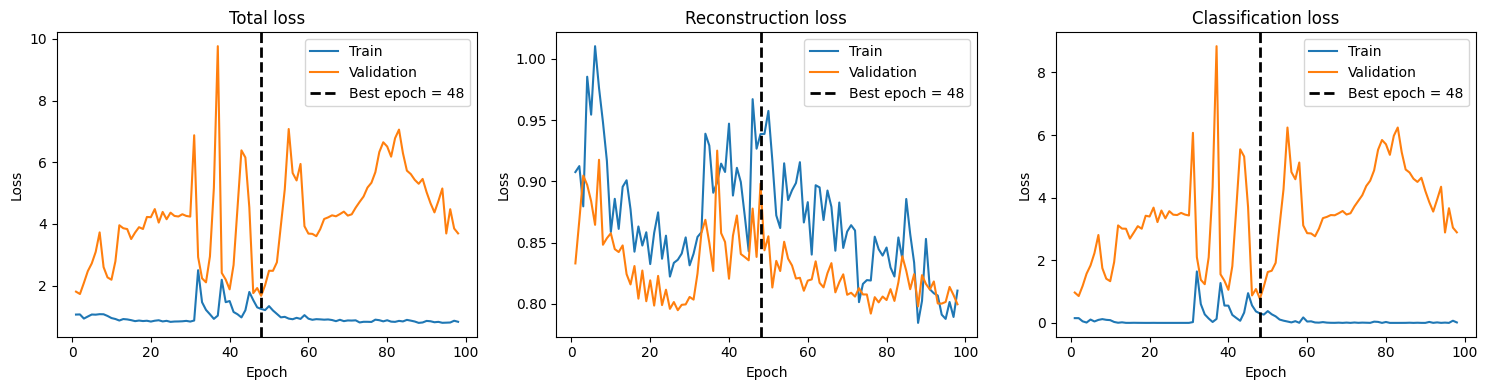

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

loss_pairs = {
    "Total loss": ("train_total_loss", "val_total_loss"),
    "Reconstruction loss": ("train_reconstruction_loss", "val_reconstruction_loss"),
    "Classification loss": ("train_classification_loss", "val_classification_loss")
}

for ax, (title, (train_col, val_col)) in zip(axes, loss_pairs.items()):
    # Graficar las losses de training y validation
    ax.plot(
        training_history["epoch"],
        training_history[train_col],
        label="Train"
    )

    ax.plot(
        training_history["epoch"],
        training_history[val_col],
        label="Validation"
    )

    # Marcar la mejor epoch
    ax.axvline(
        x=best_epoch,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Best epoch = {best_epoch}"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluar el modelo final en el test set
model.eval()

with torch.no_grad():
    _, test_logits, test_latent = model(X_test_tensor)

    # Obtener probabilidades y predicciones
    test_prob = torch.sigmoid(test_logits).detach().cpu().numpy().ravel()
    test_pred = (test_prob >= 0.5).astype(int)

y_test_np = y_test.values

positive_class = 1
negative_class = 0

# Calcular y mostrar las métricas de evaluación
autoencoder_results = {
    "AUC": roc_auc_score(y_test_np, test_prob),
    "Accuracy": accuracy_score(y_test_np, test_pred),
    "Kappa": cohen_kappa_score(y_test_np, test_pred),
    "Sensitivity": recall_score(y_test_np, test_pred, pos_label=positive_class),
    "Specificity": recall_score(y_test_np, test_pred, pos_label=negative_class)
}

autoencoder_results = pd.DataFrame(
    autoencoder_results,
    index=["Classifier_Autoencoder"]
)

display(autoencoder_results.round(3))

,AUC,Accuracy,Kappa,Sensitivity,Specificity
Classifier_Autoencoder,0.742,0.699,0.202,0.318,0.863


Representa la proyección bidimensional del latent space del mejor modelo seleccionado mediante early stopping.

In [ ]:
model.eval()

with torch.no_grad():
    # Extraer las representaciones latentes
    z_train = model.encoder(X_train_tensor.to(device))
    z_test = model.encoder(X_test_tensor.to(device))

# Convertir a NumPy y crear DataFrames
z_train = z_train.detach().cpu().numpy()
z_test = z_test.detach().cpu().numpy()

z_train_df = pd.DataFrame(
    z_train,
    columns=[f"Latent_{i+1}" for i in range(z_train.shape[1])]
)

z_train_df["Class"] = list(y_train)
z_train_df["Set"] = "Train"

z_test_df = pd.DataFrame(
    z_test,
    columns=[f"Latent_{i+1}" for i in range(z_test.shape[1])]
)

z_test_df["Class"] = list(y_test)
z_test_df["Set"] = "Test"

# Concatenar y añadir las etiquetas de clase
latent_df = pd.concat(
    [z_train_df, z_test_df],
    axis=0,
    ignore_index=True
)

latent_df["Class_label"] = latent_df["Class"].map({
    0: "No recurrence",
    1: "Recurrence"
})

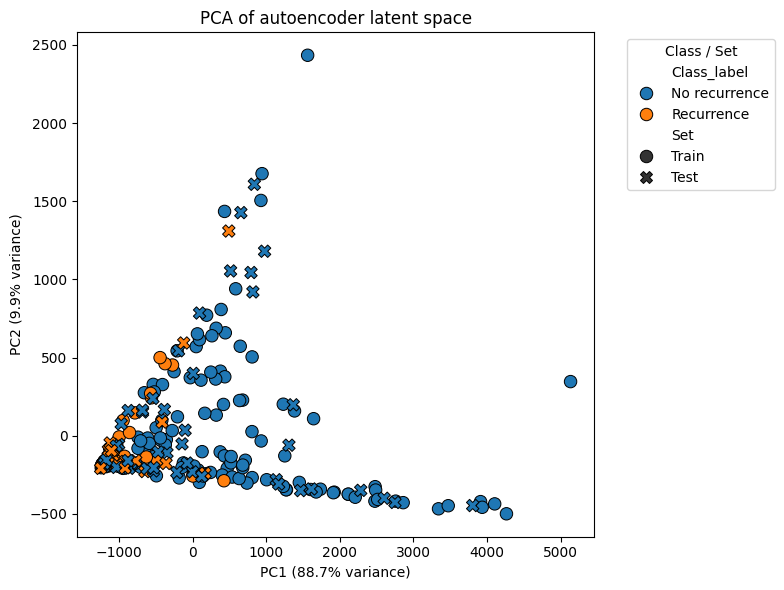

In [ ]:
latent_features = latent_df.filter(regex="^Latent_")

pca_latent = PCA(n_components=2)
latent_pca = pca_latent.fit_transform(latent_features)

latent_pca_df = pd.DataFrame(
    latent_pca,
    columns=["PC1", "PC2"]
)

latent_pca_df["Class_label"] = latent_df["Class_label"]
latent_pca_df["Set"] = latent_df["Set"]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=latent_pca_df,
    x="PC1",
    y="PC2",
    hue="Class_label",
    style="Set",
    s=80,
    edgecolor="black"
)

plt.title("PCA of autoencoder latent space")
plt.xlabel(f"PC1 ({pca_latent.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_latent.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.legend(title="Class / Set", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Repite éste ejercicio con alguna modificación a la arquitectura del autoencoder. Verifica su desempeño e incluye el criterio que usaste para los cambios. Discute los resultados comparándolo con todos los modelos usados anteriormente.

> *⏱️ Tiempo estimado: 15 minutos*